### MNIST

In [1]:
from sklearn.datasets import fetch_openml

In [2]:
mnist = fetch_openml("mnist_784",as_frame=False)

In [3]:
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [3]:
X, y = mnist.data, mnist.target

In [5]:
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784))

In [6]:
X.shape

(70000, 784)

70000 images and each image has 784 feature (each image is 28x28 pixels, 0 is balck, 255 is white)

In [7]:
y

array(['5', '0', '4', ..., '4', '5', '6'], shape=(70000,), dtype=object)

In [8]:
y.shape

(70000,)

In [4]:
import matplotlib.pyplot as plt

In [22]:
def show_image(img_arr):
    img = img_arr.reshape(28,28)
    plt.imshow(img,cmap='binary')
    plt.axis('off')

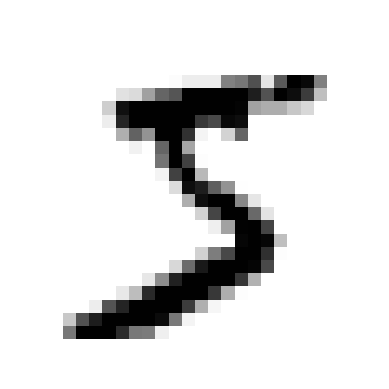

In [11]:
some_digit = X[0]
show_image(some_digit)
plt.show()

In [12]:
y[0]

'5'

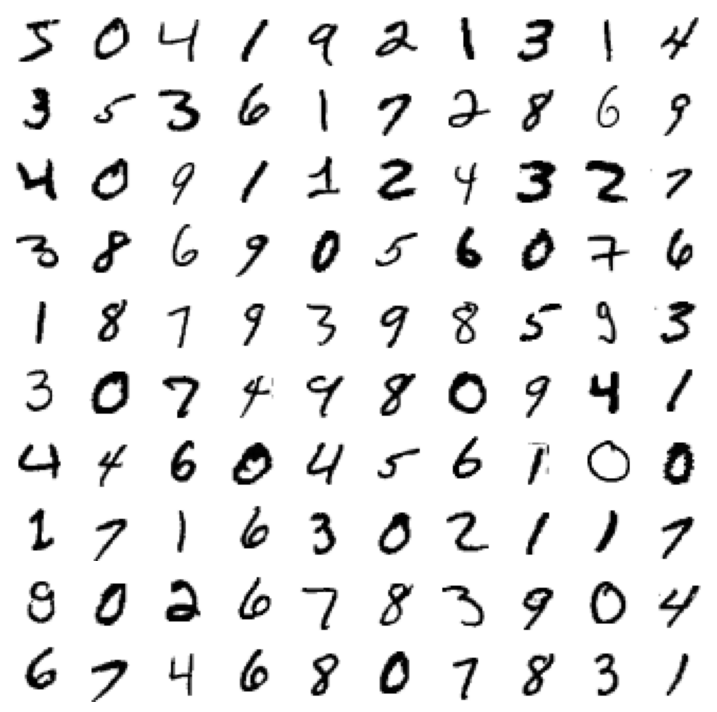

In [13]:
plt.figure(figsize=(9,9))
for idx,value in enumerate(X[:100]):
    plt.subplot(10,10,idx+1)
    show_image(value)
plt.show()

In [5]:
X_train, X_test, y_train,y_test = X[:60000], X[60000:], y[:60000], y[60000:]

### Training a Binary Classifier

Now we do binary classification. we take 2 classed 5 and non 5. 

In [5]:
# create target data
y_train_5 = (y_train=='5') # True if 5 otherwise False
y_test_5 = (y_test=='5')

In [16]:
from sklearn.linear_model import SGDClassifier
# it is not a new algorithm, based on loss function it behaves like logestic, svm,etc. it uses SGD optimization instead SD.
# It go through every examples and update

In [17]:
classifier = SGDClassifier(loss='hinge',max_iter=1000,random_state=42) # loss is hinge so, it is linear svm

In [18]:
classifier.fit(X_train,y_train_5)

,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


In [19]:
classifier.predict([some_digit]) # true means 5, false means non 5

array([ True])

### Performance Measures

#### Measuring Accuracy Using Cross-Validation

In [27]:
from sklearn.model_selection import cross_val_score

In [21]:
cross_val_score(classifier,X_train,y_train_5,cv=3,scoring="accuracy")

array([0.95035, 0.96035, 0.9604 ])

clone:
Creates a fresh, untrained copy of a model\
Same hyperparameters\
No learned weights

In [22]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

In [23]:
# implementation of cross_val_score(scoring="accuracy")
sk_folds = StratifiedKFold(3) # add shuffle=True if the dataset is not already shuffled
for train_index, test_index in sk_folds.split(X_train,y_train_5):
    clone_classifier = clone(classifier)
    X_train_folds = X_train[train_index]
    y_train_folds = y_train_5[train_index]

    X_test_folds = X_train[test_index]
    y_test_folds = y_train_5[test_index]
    clone_classifier.fit(X_train_folds,y_train_folds)
    y_pred = clone_classifier.predict(X_test_folds)
    y_correct = sum(y_test_folds==y_pred) # don't use [] like sum([y_test_folds==y_pred])
    print(y_correct/len(y_pred))

0.95035
0.96035
0.9604


In MNIST:Digit 5 ≈ 10% ,Digits not-5 ≈ 90%. So the dataset is skewed / imbalanced.\
DummyClassifier does not learn anything. It just predicts the most frequent class every time.In this case:Most frequent class = not-5, So it predicts “not-5” for every image.91% accuracy With zero intelligence, With no learning, With no image understanding

In [24]:
from sklearn.dummy import DummyClassifier
dummy_cls = DummyClassifier()
dummy_cls.fit(X_train,y_train_5)# .fit() only looks at class frequencies.It learns:“Most labels are False (not True)”
print(any(dummy_cls.predict(X_test))) # checks if at least one prediction is True (5). else False  

False


False means It never predicts a 5 — not even once

In [25]:
cross_val_score(dummy_cls,X_train,y_train_5,cv=3,scoring="accuracy")

array([0.90965, 0.90965, 0.90965])

91% accuracy, With zero intelligence, With no learning, With no image understanding

Accuracy is often the WRONG metric for classification. Especially when: Classes are imbalanced,Minority class matters (like detecting 5s). \
A dumb model can get very high accuracy. because of this problem we move to another.

#### Confusion Matrices

To compute the confusion matrix, you first need to have a set of predictions
so that they can be compared to the actual targets. You could make
predictions on the test set, but it’s best to keep that untouched for now. Instead, you
can use the cross_val_predict() function:

In [15]:
from sklearn.model_selection import cross_val_predict

In [27]:
y_train_pred = cross_val_predict(classifier,X_train,y_train_5,cv=3)

Just like the cross_val_score() function, cross_val_predict() performs k-fold
cross-validation, but instead of returning the evaluation scores, it returns the
predictions made on each test fold.

In [28]:
y_train_pred

array([ True, False, False, ...,  True, False, False], shape=(60000,))

In [29]:
y_train_5.shape,y_train_pred.shape

((60000,), (60000,))

In [30]:
from sklearn.metrics import confusion_matrix

In [31]:
cm = confusion_matrix(y_train_5, y_train_pred)

In [32]:
cm

array([[53892,   687],
       [ 1891,  3530]])

Each row in a confusion matrix represents an actual class, while each column represents a predicted class.

In [33]:
y_train_perfect = y_train_5
confusion_matrix(y_train_5,y_train_perfect)

array([[54579,     0],
       [    0,  5421]])

#### Precision and Recall

In [34]:
from sklearn.metrics import precision_score, recall_score

In [35]:
precision_score(y_train_5, y_train_pred)

0.8370879772350012

In [36]:
recall_score(y_train_5, y_train_pred)

0.6511713705958311

In [17]:
from sklearn.metrics import f1_score

In [38]:
f1_score(y_train_5, y_train_pred)

0.7325171197343847

#### The Precision/Recall Trade-off

SGDClassifier makes its
classification decisions. For each instance, it computes a score based on a
decision function. If that score is greater than a threshold, it assigns the
instance to the positive class; otherwise it assigns it to the negative class.

In [39]:
y_score = classifier.decision_function([some_digit])
y_score

array([2164.22030239])

In [40]:
threshold = 0
y_some_digit_pred = (y_score>threshold)
y_some_digit_pred

array([ True])

In [41]:
threshold = 3000
y_some_digit_pred = (y_score>threshold)
y_some_digit_pred

array([False])

“First, I use cross_val_predict to get unbiased confidence scores for each training sample.
Then I use precision_recall_curve to evaluate how precision and recall change for different decision thresholds.
By plotting precision and recall versus threshold, I can choose a threshold that best balances false positives and false negatives for my specific problem.” \
cross_val_predict gives honest scores, precision_recall_curve evaluates all thresholds, and the plot helps choose a threshold that matches business needs.

In [42]:
# use the cross_val_predict() function to get the scores of all instances in the training set
y_score = cross_val_predict(classifier, X_train, y_train_5,method="decision_function")

In [43]:
y_score[:5]

array([  4411.53413566, -14087.12193543, -21565.51993633,  -9680.87213443,
        -8000.47152133])

In [44]:
# precision_recall_curve() function to compute precision and recall for all possible thresholds
from sklearn.metrics import precision_recall_curve

In [45]:
# try every possible threshold and see what precision and recall we get
precision, recall, thresholds = precision_recall_curve(y_train_5, y_score)

In [46]:
precision,recall,thresholds

(array([0.09035   , 0.09035151, 0.09035301, ..., 1.        , 1.        ,
        1.        ], shape=(60001,)),
 array([1.00000000e+00, 1.00000000e+00, 1.00000000e+00, ...,
        3.68935621e-04, 1.84467810e-04, 0.00000000e+00], shape=(60001,)),
 array([-116288.54262534, -112139.56842955, -110416.13704754, ...,
          28900.06013894,   31207.1376772 ,   33370.36083388],
       shape=(60000,)))

In [47]:
precision[:-1]

array([0.09035   , 0.09035151, 0.09035301, ..., 1.        , 1.        ,
       1.        ], shape=(60000,))

In [58]:
import numpy as np

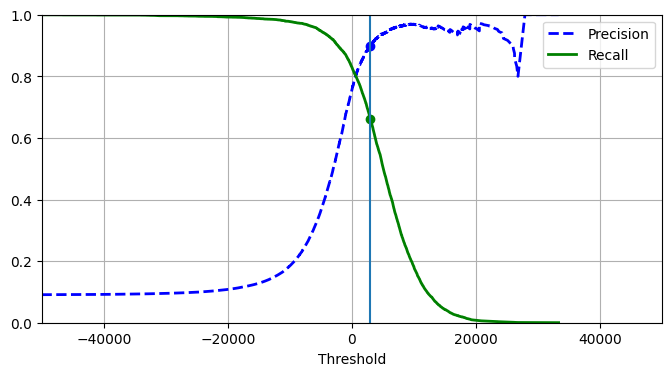

In [49]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds,precision[:-1],"b--",label="Precision", linewidth=2) # precision have one extra value, so we remove last one
plt.plot(thresholds,recall[:-1],"g-",label="Recall", linewidth=2)
idx = (thresholds >= threshold).argmax() # first index ≥ threshold # return max value inx # thresholds >= threshold are, False values first after condition True values.
plt.plot(threshold,precision[idx],"bo")
plt.plot(threshold,recall[idx],"go")
plt.vlines(x = threshold, ymin=0,ymax=1)
plt.axis([-50000,50000,0,1])
plt.xlabel("Threshold")
plt.legend()
plt.grid()
plt.show()

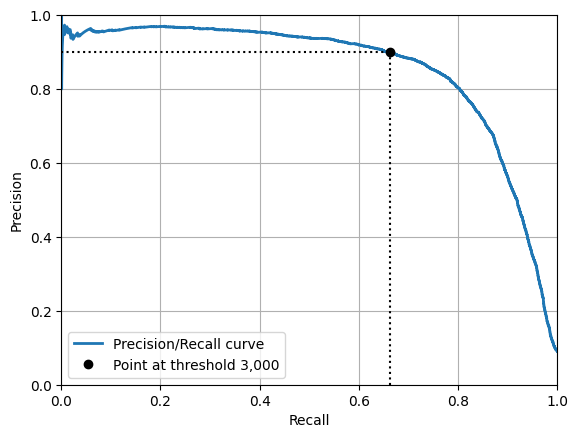

In [50]:
plt.plot(recall, precision, linewidth=2, label="Precision/Recall curve")
x_values = [recall[idx], recall[idx]]
y_values = [0., precision[idx]]
plt.plot(x_values,y_values , "k:") # vertical line
x_values = [0,recall[idx]]
y_values = [precision[idx],precision[idx]]
plt.plot(x_values, y_values, "k:") # horizontal line
plt.plot([recall[idx]], [precision[idx]], "ko",
         label="Point at threshold 3,000") # point 
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.axis([0, 1, 0, 1])
plt.grid()
plt.show()

In [51]:
# If we want 90% precision
precision

array([0.09035   , 0.09035151, 0.09035301, ..., 1.        , 1.        ,
       1.        ], shape=(60001,))

In [52]:
inx_90_precision = (precision>=0.9).argmax() # This is the lowest threshold where precision reaches at least 90%.

In [53]:
threshold_for_90_precision = thresholds[inx_90_precision]
threshold_for_90_precision

np.float64(3045.9258227053638)

In [54]:
y_train_pred_90 = (y_score>=threshold_for_90_precision)

In [55]:
precision_score(y_train_5,y_train_pred_90)

0.9002016129032258

In [56]:
recall_score(y_train_5,y_train_pred_90)

0.6589190186312488

Use above approach when:

Business gives a hard requirement

“Precision must be ≥ 90%”

“Recall must be ≥ 95%”

False positives or false negatives are very costly

In [59]:
# we want 90% recall 
# (recall >= 0.90) → True for many early values # .argmax() → returns the FIRST True #The first True corresponds to:lowest threshold model predicts everything positive
recall_90_idx = np.where(recall>=0.90)[0][-1]
threshold_for_90_recall = thresholds[recall_90_idx]
# np.where(recall >= 0.90)[0] → all indices where recall ≥ 0.90 # [-1] → last such index
y_train_pred_90_recall = (y_score>=threshold_for_90_recall)
print("precision_score:",precision_score(y_train_5,y_train_pred_90_recall))
print("recall_score:",recall_score(y_train_5,y_train_pred_90_recall))

precision_score: 0.5626153136531366
recall_score: 0.9000184467810367


#### The ROC Curve

In [60]:
from sklearn.metrics import roc_curve

In [61]:
fpr, tpr, thresholds = roc_curve(y_train_5,y_score)

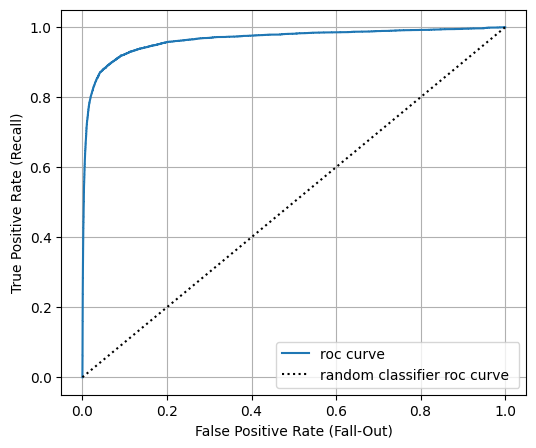

In [67]:
plt.figure(figsize=(6, 5))
plt.plot(fpr,tpr,label="roc curve")
plt.plot([0,1],[0,1],"k:",label="random classifier roc curve ")
plt.legend()
plt.xlabel('False Positive Rate (Fall-Out)')
plt.ylabel('True Positive Rate (Recall)')
plt.grid()
plt.show()

In [68]:
from sklearn.metrics import roc_auc_score

In [69]:
roc_auc_score(y_train_5,y_score)

0.9648211175804801

Since the ROC curve is so similar to the precision/recall (PR) curve, you may wonder how
to decide which one to use. As a rule of thumb, you should prefer the PR curve whenever
the positive class is rare or when you care more about the false positives than the false
negatives. Otherwise, use the ROC curve. For example, looking at the previous ROC
curve (and the ROC AUC score), you may think that the classifier is really good. But this
is mostly because there are few positives (5s) compared to the negatives (non-5s). In
contrast, the PR curve makes it clear that the classifier has room for improvement:

#### Multiclass Classification

In [6]:
from sklearn.svm import SVC # SVC uses OneVsOneClassifier, for 9 labels there are 45 classifiers

In [7]:
svm_clf = SVC(random_state=42)

In [8]:
svm_clf.fit(X_train[:2000],y_train[:2000])

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [9]:
svm_clf.predict([X[0]])

array(['5'], dtype=object)

In [10]:
svm_clf.decision_function([X[0]])

array([[ 3.79297828,  0.72949369,  6.06184129,  8.29800527, -0.29383983,
         9.30157597,  1.74723215,  2.77365456,  7.20601456,  4.82245092]])

In [11]:
svm_clf.decision_function([X[0]]).argmax() # return index which contains highest value

np.int64(5)

In [12]:
svm_clf.classes_

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype=object)

In [13]:
# OneVsRestClassifier
from sklearn.multiclass import OneVsRestClassifier

In [14]:
ovr_clf = OneVsRestClassifier(SVC(random_state=42))

In [16]:
ovr_clf.fit(X_train[:2000],y_train[:2000])

,estimator,SVC(random_state=42)
,n_jobs,None
,verbose,0
,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001


In [18]:
ovr_clf.predict([X[0]])

array(['5'], dtype='<U1')

In [20]:
ovr_clf.estimators_ # 10 OneVsRestClassifier 

[SVC(random_state=42),
 SVC(random_state=42),
 SVC(random_state=42),
 SVC(random_state=42),
 SVC(random_state=42),
 SVC(random_state=42),
 SVC(random_state=42),
 SVC(random_state=42),
 SVC(random_state=42),
 SVC(random_state=42)]

In [21]:
# train on SGDClassifier
from sklearn.linear_model import SGDClassifier

In [22]:
sgd_clf = SGDClassifier(random_state=42)

In [23]:
sgd_clf.fit(X_train,y_train)

,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


In [25]:
sgd_clf.predict([X[0]]) # wrong predicit

array(['3'], dtype='<U1')

In [26]:
sgd_clf.decision_function([X[0]])

array([[-31893.03095419, -34419.69069632,  -9530.63950739,
          1823.73154031, -22320.14822878,  -1385.80478895,
        -26188.91070951, -16147.51323997,  -4604.35491274,
        -12050.767298  ]])

In [28]:
# this take a few minutes
cross_val_score(sgd_clf,X_train,y_train,scoring="accuracy",cv=3)

array([0.87365, 0.85835, 0.8689 ])

In [34]:
from sklearn.preprocessing import StandardScaler

In [35]:
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train.astype("float64"))

In [ ]:
# # this take a few minutes
cross_val_score(sgd_clf,X_train_scaled,y_train,scoring="accuracy",cv=3)

#### Error Analysis

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay

In [36]:
# below code takes few minutes to run
y_train_pred = cross_val_predict(sgd_clf,X_train_scaled,y_train,cv=3)

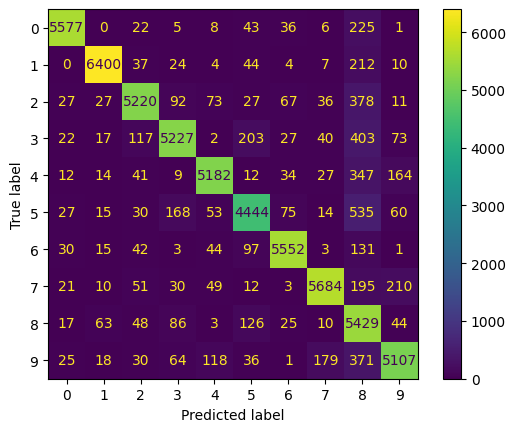

In [37]:
ConfusionMatrixDisplay.from_predictions(y_train,y_train_pred)
plt.show()

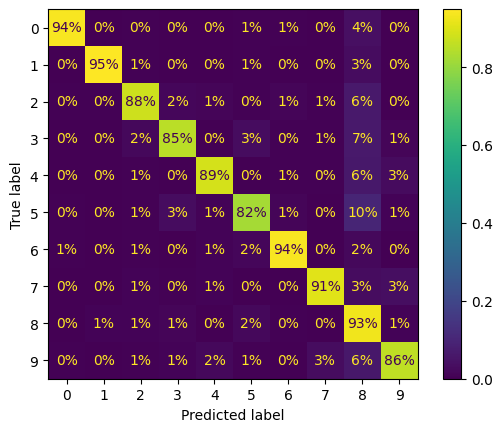

In [39]:
ConfusionMatrixDisplay.from_predictions(y_train,y_train_pred,normalize='true',values_format='.0%')
plt.show()

In [ ]:
sample_weight = (y_train_pred != y_train)
ConfusionMatrixDisplay.from_predictions(y_train,y_train_pred,sample_weight =sample_weight, normalize='true',values_format='.0%')
plt.show()

The column for class 8 is now really bright, which confirms that many
images got misclassified as 8s. \
the 36% in row #7, column #9 does not mean that
36% of all images of 7s were misclassified as 9s. It means that 36% of the
errors the model made on images of 7s were misclassifications as 9s.

### Multilabel Classification

In [6]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

In [8]:
y_train_large = (y_train >= '7')
y_train_odd = (y_train.astype('int8')%2==1)

In [10]:
y_multi_label = np.c_[y_train_large, y_train_odd]
y_multi_label[:2]

array([[False,  True],
       [False, False]])

In [11]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train,y_multi_label)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [13]:
knn_clf.predict([X[0]])

array([[False,  True]])

In [14]:
y[0]

'5'

In [16]:
y_train_knn_pred = cross_val_predict(knn_clf,X_train,y_multi_label,cv=3)

In [19]:
# f1_score average for all labels(2 labels in this case)
f1_score(y_multi_label,y_train_knn_pred,average="macro")

0.9764102655606048

### Multioutput Classification

a system that removes noise from images. It will
take as input a noisy digit image, and it will (hopefully) output a clean digit
image, represented as an array of pixel intensities

In [24]:
np.random.seed(42)
noise = np.random.randint(low=0,high=100,size=(len(X_train),784))
X_train_mod = X_train+noise
noise = np.random.randint(low=0,high=100,size=(len(X_test),784))
X_test_mod = X_test+noise
y_train_mod = X_train # real X_train as output
y_test_mod = X_test

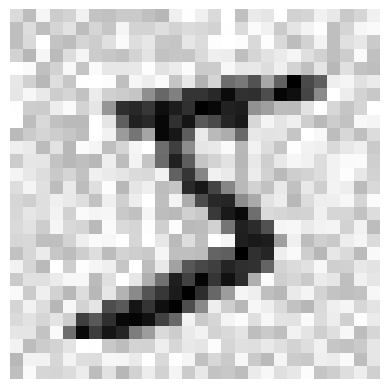

In [25]:
show_image(X_train_mod[0]) # noised image

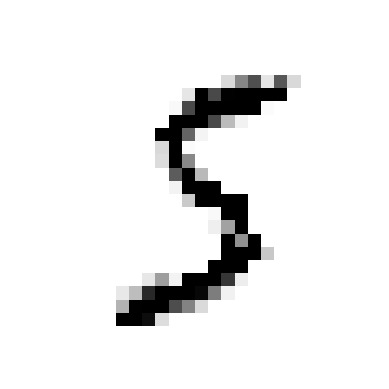

In [26]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train_mod, y_train_mod)
clean_digit = knn_clf.predict([X_train_mod[0]])
show_image(clean_digit)